In [1]:
import os
import sys
import utils
import random
import numpy as np
import pandas as pd
import seaborn as sn
import nivapy3 as nivapy
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

sys.path.append("..")
plt.style.use("ggplot")

In [2]:
def double_mad_from_median(data, thresh=3.5):
    """Simple test for outliers in 1D data. Based on the standard MAD approach, but
    modified slightly to allow for skewed datasets.
    """
    m = np.nanmedian(data)
    abs_dev = np.abs(data - m)
    left_mad = np.median(abs_dev[data <= m])
    right_mad = np.median(abs_dev[data >= m])
    if (left_mad == 0) or (right_mad == 0):
        return np.zeros_like(data, dtype=bool)

    data_mad = left_mad * np.ones(len(data))
    data_mad[data > m] = right_mad
    modified_z_score = 0.6745 * abs_dev / data_mad
    modified_z_score[data == m] = 0

    return modified_z_score > thresh


def calculate_years_of_observations(df, var):
    return df[df[var].notnull()].groupby('WaterLocationID')['year'].nunique()


def detect_outliers(group, column, thresh=4):
    data = group[column]
    non_nan_data = data.dropna()
    outliers = double_mad_from_median(non_nan_data.values, thresh)
    outliers_series = pd.Series(outliers, index=non_nan_data.index)
    return outliers_series.reindex(group.index, fill_value=np.nan)


def plot_site_data(df, site_id, var, outlier_columns, ax):
    site_data = df[df['WaterLocationID'] == site_id]
    outlier_col = outlier_columns[var]
    inliers = site_data[site_data[outlier_col] == False]
    outliers = site_data[site_data[outlier_col] == True]

    ax.scatter(inliers['SamplingTime'], inliers[var], color='blue', label='Inliers')
    ax.scatter(outliers['SamplingTime'], outliers[var], color='red', label='Outliers')
    ax.set_xlabel('Sampling Time')
    ax.set_ylabel(var)
    ax.set_title(f'Location id {site_id}')
    ax.legend()
    ax.grid(True)

In [3]:
column_mapping = {
    'N-TOT_µg_l': 'site_outliers_ntot',
    'P-TOT_µg_l': 'site_outliers_ptot',
    'TOC_mg_l': 'site_outliers_toc'
}

# Identify outliers using Mean Absolute Error (MAD)
* Screening across all sites at the same time to highlight obvious unit errors in Vannmiljø (values are wrong by a factor of 1000)
* Screening considering sites individually

In [4]:
# Users input 
fpath= "../data/cleaned/water_chemistry/ai_wc_selected_sites.xlsx"

variables = ['N-TOT_µg_l', 'P-TOT_µg_l', 'TOC_mg_l']

new_order = ['WaterLocationID', 'WaterLocationCode', 'Name', 'ActivityID', 'ActivityName', 
             'MediumID', 'WaterCategory', 'SamplingTime', 'lon', 'lat', 'UpperDepth', 'LowerDepth', 
             'N-TOT_µg_l', 'global_outliers_ntot', 'site_outliers_ntot',
             'P-TOT_µg_l', 'global_outliers_ptot', 'site_outliers_ptot',
             'TOC_mg_l', 'global_outliers_toc', 'site_outliers_toc']

In [5]:
# Read df
df = pd.read_excel(fpath)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 326552 entries, 0 to 326551
Data columns (total 18 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Unnamed: 0         326552 non-null  int64  
 1   WaterLocationID    326552 non-null  int64  
 2   WaterLocationCode  326552 non-null  object 
 3   Name               326552 non-null  object 
 4   ActivityID         326552 non-null  object 
 5   ActivityName       326552 non-null  object 
 6   MediumID           326552 non-null  object 
 7   SamplingTime       326552 non-null  object 
 8   UpperDepth         326552 non-null  float64
 9   LowerDepth         326552 non-null  float64
 10  N-TOT_µg_l         265028 non-null  float64
 11  P-TOT_µg_l         281554 non-null  float64
 12  DOC_mg_l           7908 non-null    float64
 13  TOC_mg_l           190452 non-null  float64
 14  lon                326552 non-null  float64
 15  lat                326552 non-null  float64
 16  Wa

## 1. Check for negative and missing values

In [6]:
# Unique dates format 
df['SamplingTime'] = df['SamplingTime'].str.split(' ').str[0]
df['SamplingTime'] = pd.to_datetime(df['SamplingTime'], format='%Y-%m-%d')

# Drop unnecessary columns 
columns_to_drop = ['Unnamed: 0', 'DOC_mg_l', 'lon_lat']
df = df.drop(columns=columns_to_drop)

# Check for negative values
negative_counts = {
    'N-TOT_µg_l': ((df['N-TOT_µg_l'] < 0) & df['N-TOT_µg_l'].notna()).sum(),
    'P-TOT_µg_l': ((df['P-TOT_µg_l'] < 0) & df['P-TOT_µg_l'].notna()).sum(),
    'TOC_mg_l': ((df['TOC_mg_l'] < 0) & df['TOC_mg_l'].notna()).sum()
}
print("Negative data count for each variable:")
print(negative_counts)

# Check for missing data
def check_missing_data(df):
    missing_data = df.isnull().sum()
    print("\nMissing data count for each column:")
    print(missing_data)
check_missing_data(df)

Negative data count for each variable:
{'N-TOT_µg_l': 0, 'P-TOT_µg_l': 0, 'TOC_mg_l': 0}

Missing data count for each column:
WaterLocationID           0
WaterLocationCode         0
Name                      0
ActivityID                0
ActivityName              0
MediumID                  0
SamplingTime              0
UpperDepth                0
LowerDepth                0
N-TOT_µg_l            61524
P-TOT_µg_l            44998
TOC_mg_l             136100
lon                       0
lat                       0
WaterCategory             0
dtype: int64


## 2. Filter out rows pre-1980

In [7]:
df = df[df['SamplingTime'].dt.year >= 1980]
df.head()

,WaterLocationID,WaterLocationCode,Name,ActivityID,ActivityName,MediumID,SamplingTime,UpperDepth,LowerDepth,N-TOT_µg_l,P-TOT_µg_l,TOC_mg_l,lon,lat,WaterCategory
88,27839,001-27839,Bjørkelangen (BJØ1),ANNE,Annet,VF,1980-02-20,0.0,0.0,1280.0,54.0,NaN,11.532832,59.848034,L
89,27839,001-27839,Bjørkelangen (BJØ1),ANNE,Annet,VF,1980-02-20,1.0,1.0,1440.0,52.0,NaN,11.532832,59.848034,L
90,27839,001-27839,Bjørkelangen (BJØ1),ANNE,Annet,VF,1980-02-20,2.0,2.0,1560.0,43.0,NaN,11.532832,59.848034,L
91,27839,001-27839,Bjørkelangen (BJØ1),ANNE,Annet,VF,1980-02-20,5.0,5.0,1560.0,43.0,NaN,11.532832,59.848034,L
92,27839,001-27839,Bjørkelangen (BJØ1),ANNE,Annet,VF,1980-02-20,7.0,7.0,1520.0,46.0,NaN,11.532832,59.848034,L


## 3. Raw data distributions by water category

In [8]:
# Select water category
df_R = df[df['WaterCategory'] == 'R']
df_L = df[df['WaterCategory'] == 'L']

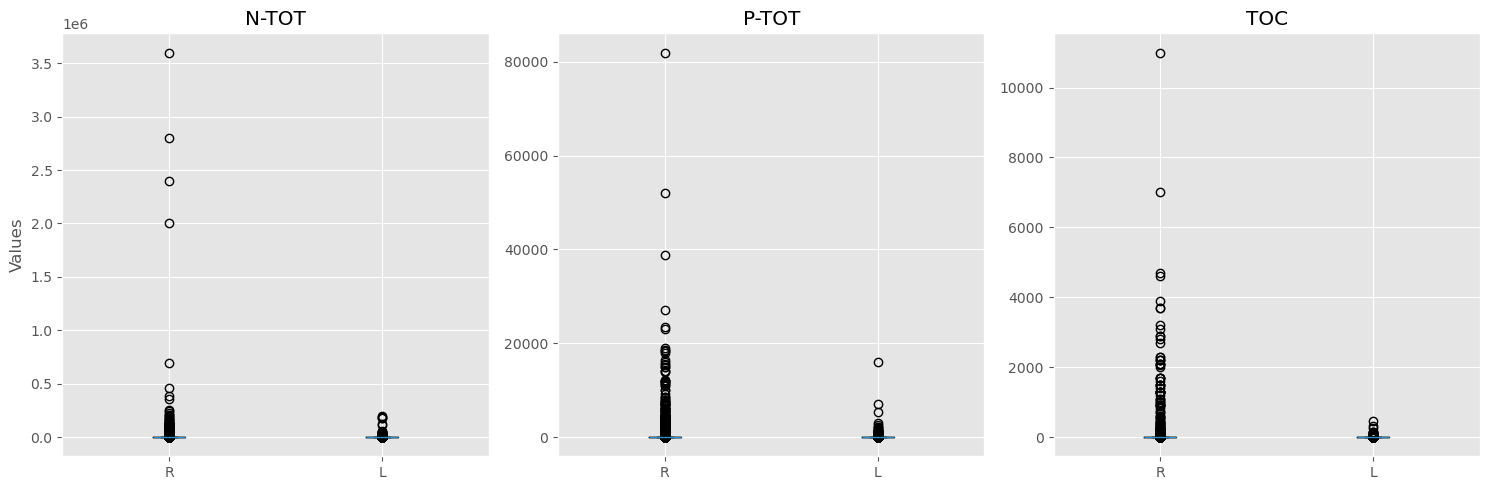

In [9]:
# Boxplots showing outliers
plt.figure(figsize=(15, 5))

# N-TOT boxplots
plt.subplot(1, 3, 1)
plt.boxplot([df_R['N-TOT_µg_l'].dropna(), df_L['N-TOT_µg_l'].dropna()], labels=['R', 'L'], showfliers=True)
plt.title('N-TOT')
plt.ylabel('Values')

# P-TOT boxplots
plt.subplot(1, 3, 2)
plt.boxplot([df_R['P-TOT_µg_l'].dropna(), df_L['P-TOT_µg_l'].dropna()], labels=['R', 'L'], showfliers=True)
plt.title('P-TOT')

# TOC boxplots
plt.subplot(1, 3, 3)
plt.boxplot([df_R['TOC_mg_l'].dropna(), df_L['TOC_mg_l'].dropna()], labels=['R', 'L'], showfliers=True)
plt.title('TOC')

plt.tight_layout()
plt.show()

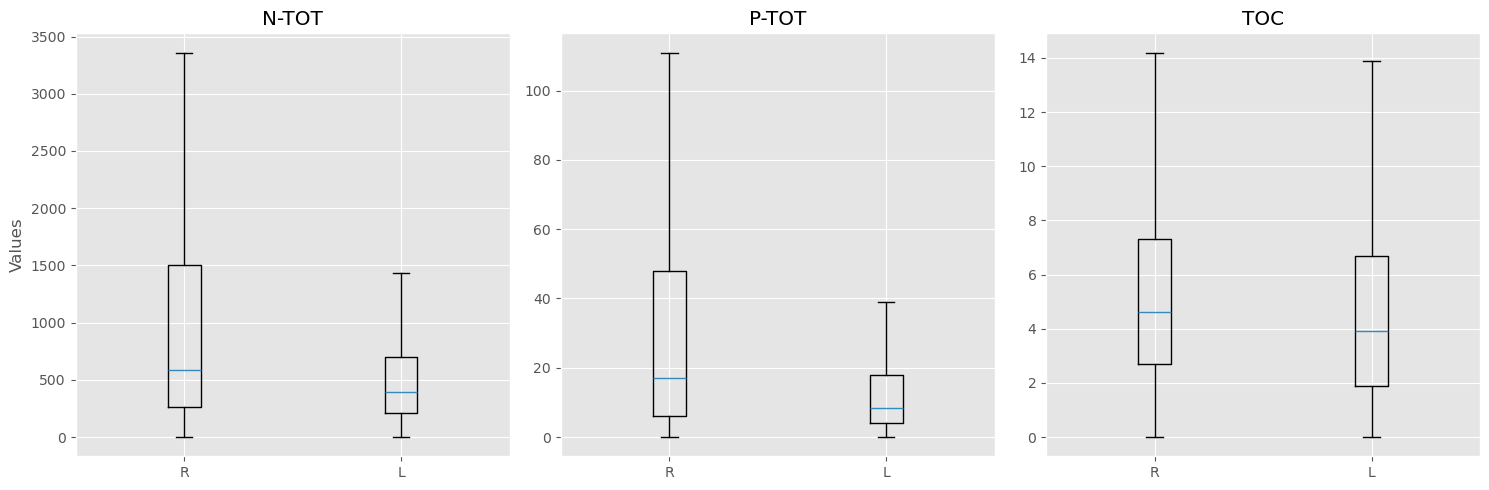

In [10]:
# Plot boxplots without showing outliers
plt.figure(figsize=(15, 5))

# N-TOT boxplots
plt.subplot(1, 3, 1)
plt.boxplot([df_R['N-TOT_µg_l'].dropna(), df_L['N-TOT_µg_l'].dropna()], labels=['R', 'L'], showfliers=False)
plt.title('N-TOT')
plt.ylabel('Values')

# P-TOT boxplots
plt.subplot(1, 3, 2)
plt.boxplot([df_R['P-TOT_µg_l'].dropna(), df_L['P-TOT_µg_l'].dropna()], labels=['R', 'L'], showfliers=False)
plt.title('P-TOT')

# TOC boxplots
plt.subplot(1, 3, 3)
plt.boxplot([df_R['TOC_mg_l'].dropna(), df_L['TOC_mg_l'].dropna()], labels=['R', 'L'], showfliers=False)
plt.title('TOC')

plt.tight_layout()
plt.show()

## 4. Outlier detection using MAD

### 4.1. Across all sites: Rivers

In [11]:
df_R.head()

,WaterLocationID,WaterLocationCode,Name,ActivityID,ActivityName,MediumID,SamplingTime,UpperDepth,LowerDepth,N-TOT_µg_l,P-TOT_µg_l,TOC_mg_l,lon,lat,WaterCategory
675,27954,001-27954,Stømselva ved Strømsfoss,TILT,Tiltaksorientert overvåking,VF,2008-10-30,0.0,0.0,NaN,20.0,NaN,11.661330,59.301617,R
817,27958,001-27958,Lierelva ved Lierfoss,TILT,Tiltaksorientert overvåking,VF,2012-05-30,0.0,0.0,530.0,26.0,NaN,11.532151,59.919631,R
818,27958,001-27958,Lierelva ved Lierfoss,TILT,Tiltaksorientert overvåking,VF,2012-06-13,0.0,0.0,NaN,34.0,NaN,11.532151,59.919631,R
819,27958,001-27958,Lierelva ved Lierfoss,TILT,Tiltaksorientert overvåking,VF,2012-06-27,0.0,0.0,2400.0,42.0,NaN,11.532151,59.919631,R
820,27958,001-27958,Lierelva ved Lierfoss,TILT,Tiltaksorientert overvåking,VF,2012-07-11,0.0,0.0,NaN,91.0,NaN,11.532151,59.919631,R


In [12]:
# Estimate outliers 
# Apply the function to each column
df_R['global_outliers_ntot'] = double_mad_from_median(df_R['N-TOT_µg_l'], thresh=4)
df_R['global_outliers_ptot'] = double_mad_from_median(df_R['P-TOT_µg_l'], thresh=4)
df_R['global_outliers_toc'] = double_mad_from_median(df_R['TOC_mg_l'], thresh=4)

# Ensure NaN values are preserved in the original columns
df_R['global_outliers_ntot'] = df_R['global_outliers_ntot'].where(~df_R['N-TOT_µg_l'].isna(), np.nan)
df_R['global_outliers_ptot'] = df_R['global_outliers_ptot'].where(~df_R['P-TOT_µg_l'].isna(), np.nan)
df_R['global_outliers_toc'] = df_R['global_outliers_toc'].where(~df_R['TOC_mg_l'].isna(), np.nan)

df_R.info()

<class 'pandas.core.frame.DataFrame'>
Index: 248568 entries, 675 to 326503
Data columns (total 18 columns):
 #   Column                Non-Null Count   Dtype         
---  ------                --------------   -----         
 0   WaterLocationID       248568 non-null  int64         
 1   WaterLocationCode     248568 non-null  object        
 2   Name                  248568 non-null  object        
 3   ActivityID            248568 non-null  object        
 4   ActivityName          248568 non-null  object        
 5   MediumID              248568 non-null  object        
 6   SamplingTime          248568 non-null  datetime64[ns]
 7   UpperDepth            248568 non-null  float64       
 8   LowerDepth            248568 non-null  float64       
 9   N-TOT_µg_l            205146 non-null  float64       
 10  P-TOT_µg_l            218262 non-null  float64       
 11  TOC_mg_l              146010 non-null  float64       
 12  lon                   248568 non-null  float64       
 13  la

/tmp/ipykernel_500/1213883501.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_R['global_outliers_ntot'] = double_mad_from_median(df_R['N-TOT_µg_l'], thresh=4)
/tmp/ipykernel_500/1213883501.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_R['global_outliers_ptot'] = double_mad_from_median(df_R['P-TOT_µg_l'], thresh=4)
/tmp/ipykernel_500/1213883501.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value inst

In [13]:
# Filter the dataframe for False and True global outliers
df_ntot_false = df_R[df_R['global_outliers_ntot'] == False]
df_ptot_false = df_R[df_R['global_outliers_ptot'] == False]
df_toc_false = df_R[df_R['global_outliers_toc'] == False]

df_ntot_true = df_R[df_R['global_outliers_ntot'] == True]
df_ptot_true = df_R[df_R['global_outliers_ptot'] == True]
df_toc_true = df_R[df_R['global_outliers_toc'] == True]

# Total number of samples vs numeber of outliers detected by MAD
print(f"The total number of samples in the dataset is: {len(df_R['N-TOT_µg_l'].dropna())}")
print(f"The total number of outliers detected is: {len(df_ntot_true)}\n")
print(f"The total number of samples in the dataset is: {len(df_R['P-TOT_µg_l'].dropna())}")
print(f"The total number of outliers detected is: {len(df_ptot_true)}\n")
print(f"The total number of samples in the dataset is: {len(df_R['TOC_mg_l'].dropna())}")
print(f"The total number of outliers detected is: {len(df_toc_true)}\n")

The total number of samples in the dataset is: 205146
The total number of outliers detected is: 6538

The total number of samples in the dataset is: 218262
The total number of outliers detected is: 9768

The total number of samples in the dataset is: 146010
The total number of outliers detected is: 1935



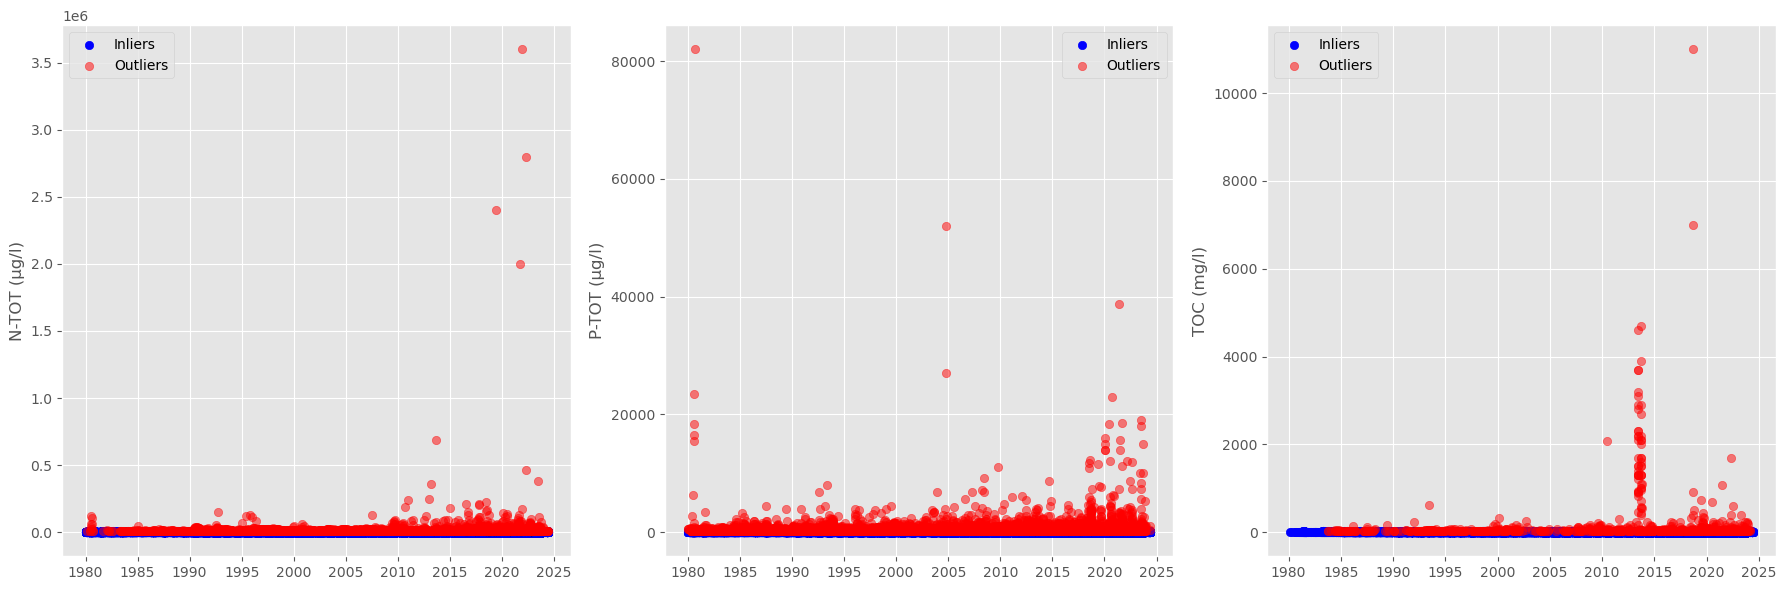

In [14]:
fig, axs = plt.subplots(1, 3, figsize=(18, 6))

# Plot for N-TOT
axs[0].scatter(df_ntot_false['SamplingTime'], df_ntot_false['N-TOT_µg_l'], color='blue', label='Inliers')
axs[0].scatter(df_ntot_true['SamplingTime'], df_ntot_true['N-TOT_µg_l'], color='red', label='Outliers', alpha= 0.5)
axs[0].set_ylabel('N-TOT (µg/l)')
axs[0].legend()

# Plot for P-TOT
axs[1].scatter(df_ptot_false['SamplingTime'], df_ptot_false['P-TOT_µg_l'], color='blue', label='Inliers')
axs[1].scatter(df_ptot_true['SamplingTime'], df_ptot_true['P-TOT_µg_l'], color='red', label='Outliers', alpha = 0.5)
axs[1].set_ylabel('P-TOT (µg/l)')
axs[1].legend()

# Plot for TOC
axs[2].scatter(df_toc_false['SamplingTime'], df_toc_false['TOC_mg_l'], color='blue', label='Inliers')
axs[2].scatter(df_toc_true['SamplingTime'], df_toc_true['TOC_mg_l'], color='red', label='Outliers', alpha = 0.5)
axs[2].set_ylabel('TOC (mg/l)')
axs[2].legend()

plt.tight_layout()
plt.show()


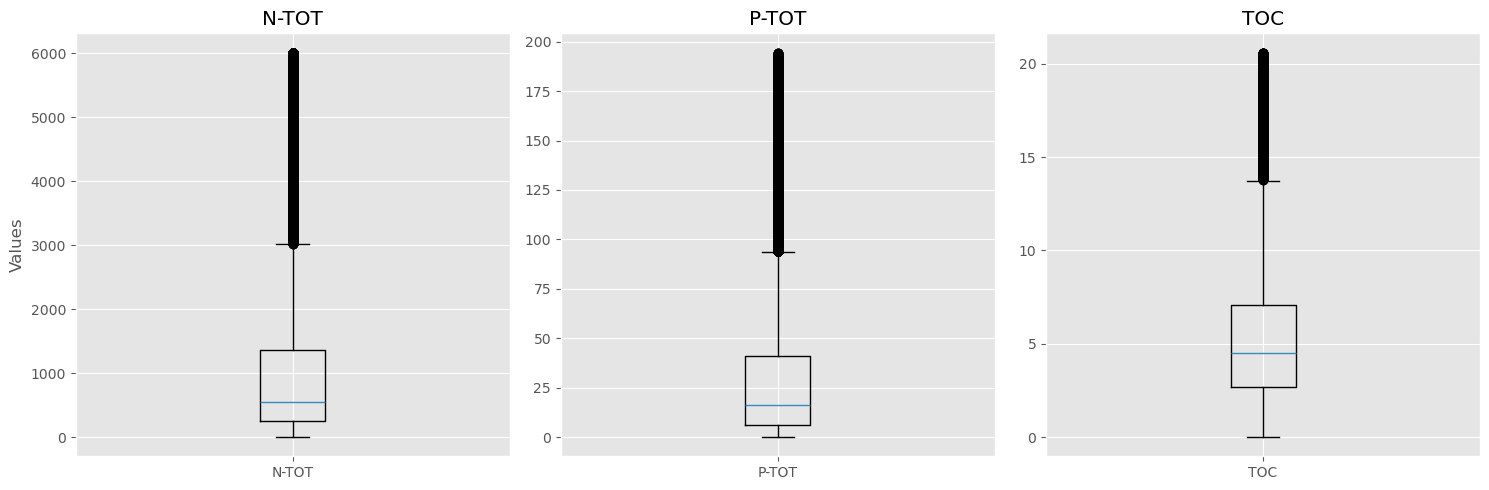

In [15]:
# Boxplots of inliers
plt.figure(figsize=(15, 5))

# Plot N-TOT boxplot
plt.subplot(1, 3, 1)
plt.boxplot(df_ntot_false['N-TOT_µg_l'].dropna(), labels=['N-TOT'])
plt.title('N-TOT')
plt.ylabel('Values')

# Plot P-TOT boxplot
plt.subplot(1, 3, 2)
plt.boxplot(df_ptot_false['P-TOT_µg_l'].dropna(), labels=['P-TOT'])
plt.title('P-TOT')

# Plot TOC boxplot
plt.subplot(1, 3, 3)
plt.boxplot(df_toc_false['TOC_mg_l'].dropna(), labels=['TOC'])
plt.title('TOC')

# Show the plots
plt.tight_layout()
plt.show()

### 4.2. Sites individually: Rivers

/tmp/ipykernel_500/3017877425.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_R['year'] = pd.to_datetime(df_R['SamplingTime']).dt.year


Number of unique water location IDs: 12209

N-TOT_µg_l: {'less_than_5': 8740, 'between_5_and_10': 974, 'between_10_and_20': 574, 'between_20_and_30': 138, 'between_30_and_40': 67, 'more_than_40': 5}

P-TOT_µg_l: {'less_than_5': 8602, 'between_5_and_10': 1033, 'between_10_and_20': 629, 'between_20_and_30': 220, 'between_30_and_40': 33, 'more_than_40': 5}

TOC_mg_l: {'less_than_5': 7222, 'between_5_and_10': 1044, 'between_10_and_20': 451, 'between_20_and_30': 83, 'between_30_and_40': 50, 'more_than_40': 2}



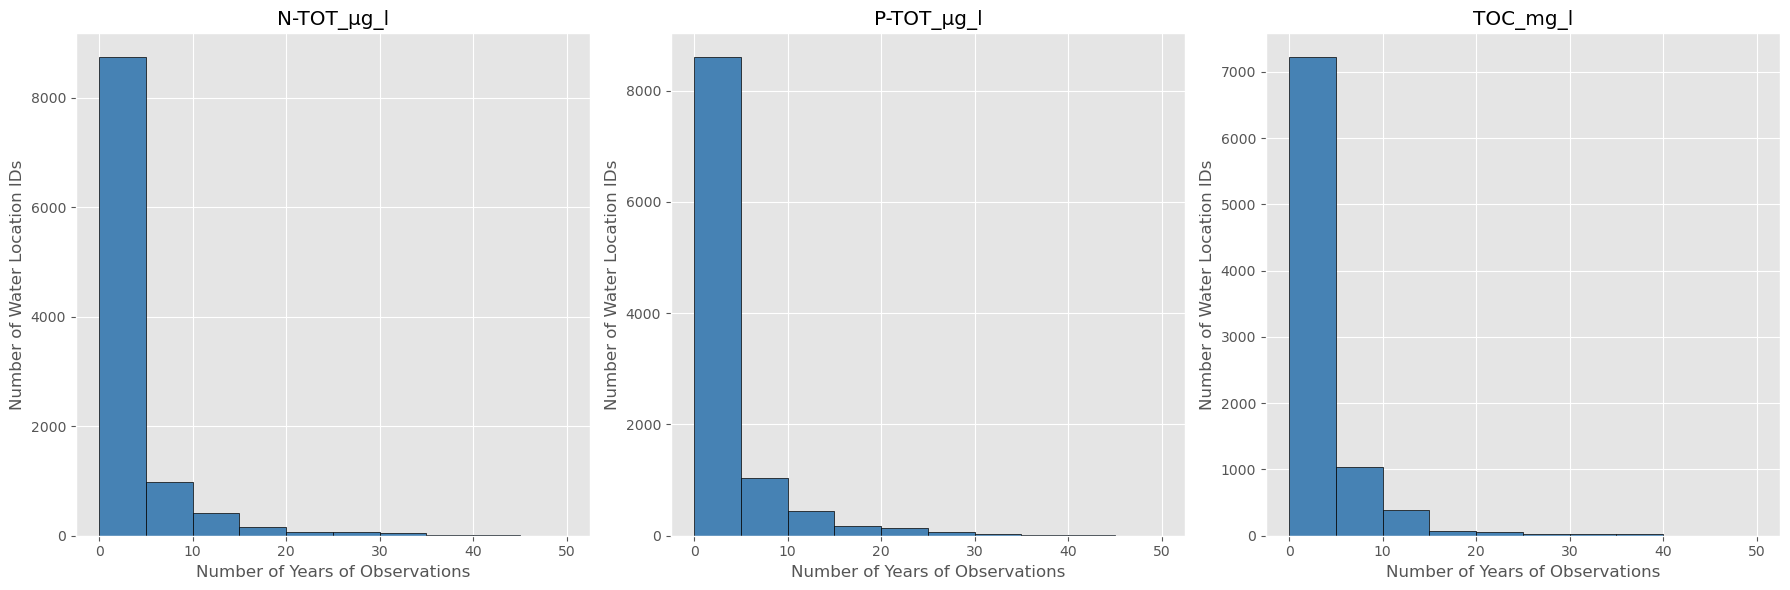

In [16]:
# Convert sampling time to year
df_R['year'] = pd.to_datetime(df_R['SamplingTime']).dt.year

# Count unique water location IDs
unique_ids = df_R['WaterLocationID'].nunique()
print(f"Number of unique water location IDs: {unique_ids}\n")

# Calculate and categorize the number of years of observations for each variable
for var in variables:
    years_of_observations = calculate_years_of_observations(df_R, var)
    categories = {
        'less_than_5': (years_of_observations < 5).sum(),
        'between_5_and_10': ((years_of_observations >= 5) & (years_of_observations < 10)).sum(),
        'between_10_and_20': ((years_of_observations >= 10) & (years_of_observations < 20)).sum(),
        'between_20_and_30': ((years_of_observations >= 20) & (years_of_observations < 30)).sum(),
        'between_30_and_40': ((years_of_observations >= 30) & (years_of_observations < 40)).sum(),
        'more_than_40': (years_of_observations >= 40).sum()
    }
    print(f"{var}: {categories}\n")

# Create subplots
fig, axs = plt.subplots(1, 3, figsize=(18, 6))

# Create histograms for each variable
for i, var in enumerate(variables):
    years_of_observations = calculate_years_of_observations(df_R, var)
    
    axs[i].hist(years_of_observations, bins=[0, 5, 10, 15, 20, 25, 30, 35, 40, 45, 50], edgecolor='black', color='steelblue')
    axs[i].set_xlabel('Number of Years of Observations')
    axs[i].set_ylabel('Number of Water Location IDs')
    axs[i].set_title(f'{var}')
    axs[i].grid(True)

plt.tight_layout()
plt.show()

In [17]:
# Apply the outlier detection function to each group and create new columns with specified names
for original_column, outlier_column in column_mapping.items():
    df_R[outlier_column] = df_R.groupby('WaterLocationID').apply(detect_outliers, column=original_column, thresh = 7).reset_index(level=0, drop=True)
    print(f"Processed column: {original_column} -> {outlier_column}")  # Debugging step to ensure each column is processed

# Check the result
df_R.head()

/opt/conda/lib/python3.11/site-packages/numpy/lib/nanfunctions.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/opt/conda/lib/python3.11/site-packages/numpy/core/fromnumeric.py:3504: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/opt/conda/lib/python3.11/site-packages/numpy/core/_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/tmp/ipykernel_500/2129875880.py:3: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_R[outlier_column] = df_R.groupby('WaterLocationID').apply(detect_outliers, column=original_column, thresh = 7).reset_index(level=0,

Processed column: N-TOT_µg_l -> site_outliers_ntot


/tmp/ipykernel_500/2129875880.py:3: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_R[outlier_column] = df_R.groupby('WaterLocationID').apply(detect_outliers, column=original_column, thresh = 7).reset_index(level=0, drop=True)
/tmp/ipykernel_500/2129875880.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_R[outlier_column] = df_R.groupby('WaterLocationID').apply(detect_outliers, column=original_column, thresh = 7).reset_index(level=0, drop=True)
/opt/

Processed column: P-TOT_µg_l -> site_outliers_ptot
Processed column: TOC_mg_l -> site_outliers_toc


/tmp/ipykernel_500/2129875880.py:3: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_R[outlier_column] = df_R.groupby('WaterLocationID').apply(detect_outliers, column=original_column, thresh = 7).reset_index(level=0, drop=True)
/tmp/ipykernel_500/2129875880.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_R[outlier_column] = df_R.groupby('WaterLocationID').apply(detect_outliers, column=original_column, thresh = 7).reset_index(level=0, drop=True)


,WaterLocationID,WaterLocationCode,Name,ActivityID,ActivityName,MediumID,SamplingTime,UpperDepth,LowerDepth,N-TOT_µg_l,...,lon,lat,WaterCategory,global_outliers_ntot,global_outliers_ptot,global_outliers_toc,year,site_outliers_ntot,site_outliers_ptot,site_outliers_toc
675,27954,001-27954,Stømselva ved Strømsfoss,TILT,Tiltaksorientert overvåking,VF,2008-10-30,0.0,0.0,NaN,...,11.661330,59.301617,R,NaN,False,NaN,2008,NaN,False,NaN
817,27958,001-27958,Lierelva ved Lierfoss,TILT,Tiltaksorientert overvåking,VF,2012-05-30,0.0,0.0,530.0,...,11.532151,59.919631,R,False,False,NaN,2012,False,False,NaN
818,27958,001-27958,Lierelva ved Lierfoss,TILT,Tiltaksorientert overvåking,VF,2012-06-13,0.0,0.0,NaN,...,11.532151,59.919631,R,NaN,False,NaN,2012,NaN,False,NaN
819,27958,001-27958,Lierelva ved Lierfoss,TILT,Tiltaksorientert overvåking,VF,2012-06-27,0.0,0.0,2400.0,...,11.532151,59.919631,R,False,False,NaN,2012,False,False,NaN
820,27958,001-27958,Lierelva ved Lierfoss,TILT,Tiltaksorientert overvåking,VF,2012-07-11,0.0,0.0,NaN,...,11.532151,59.919631,R,NaN,False,NaN,2012,NaN,False,NaN


/tmp/ipykernel_500/487048833.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_R['Year'] = df_R['SamplingTime'].dt.year


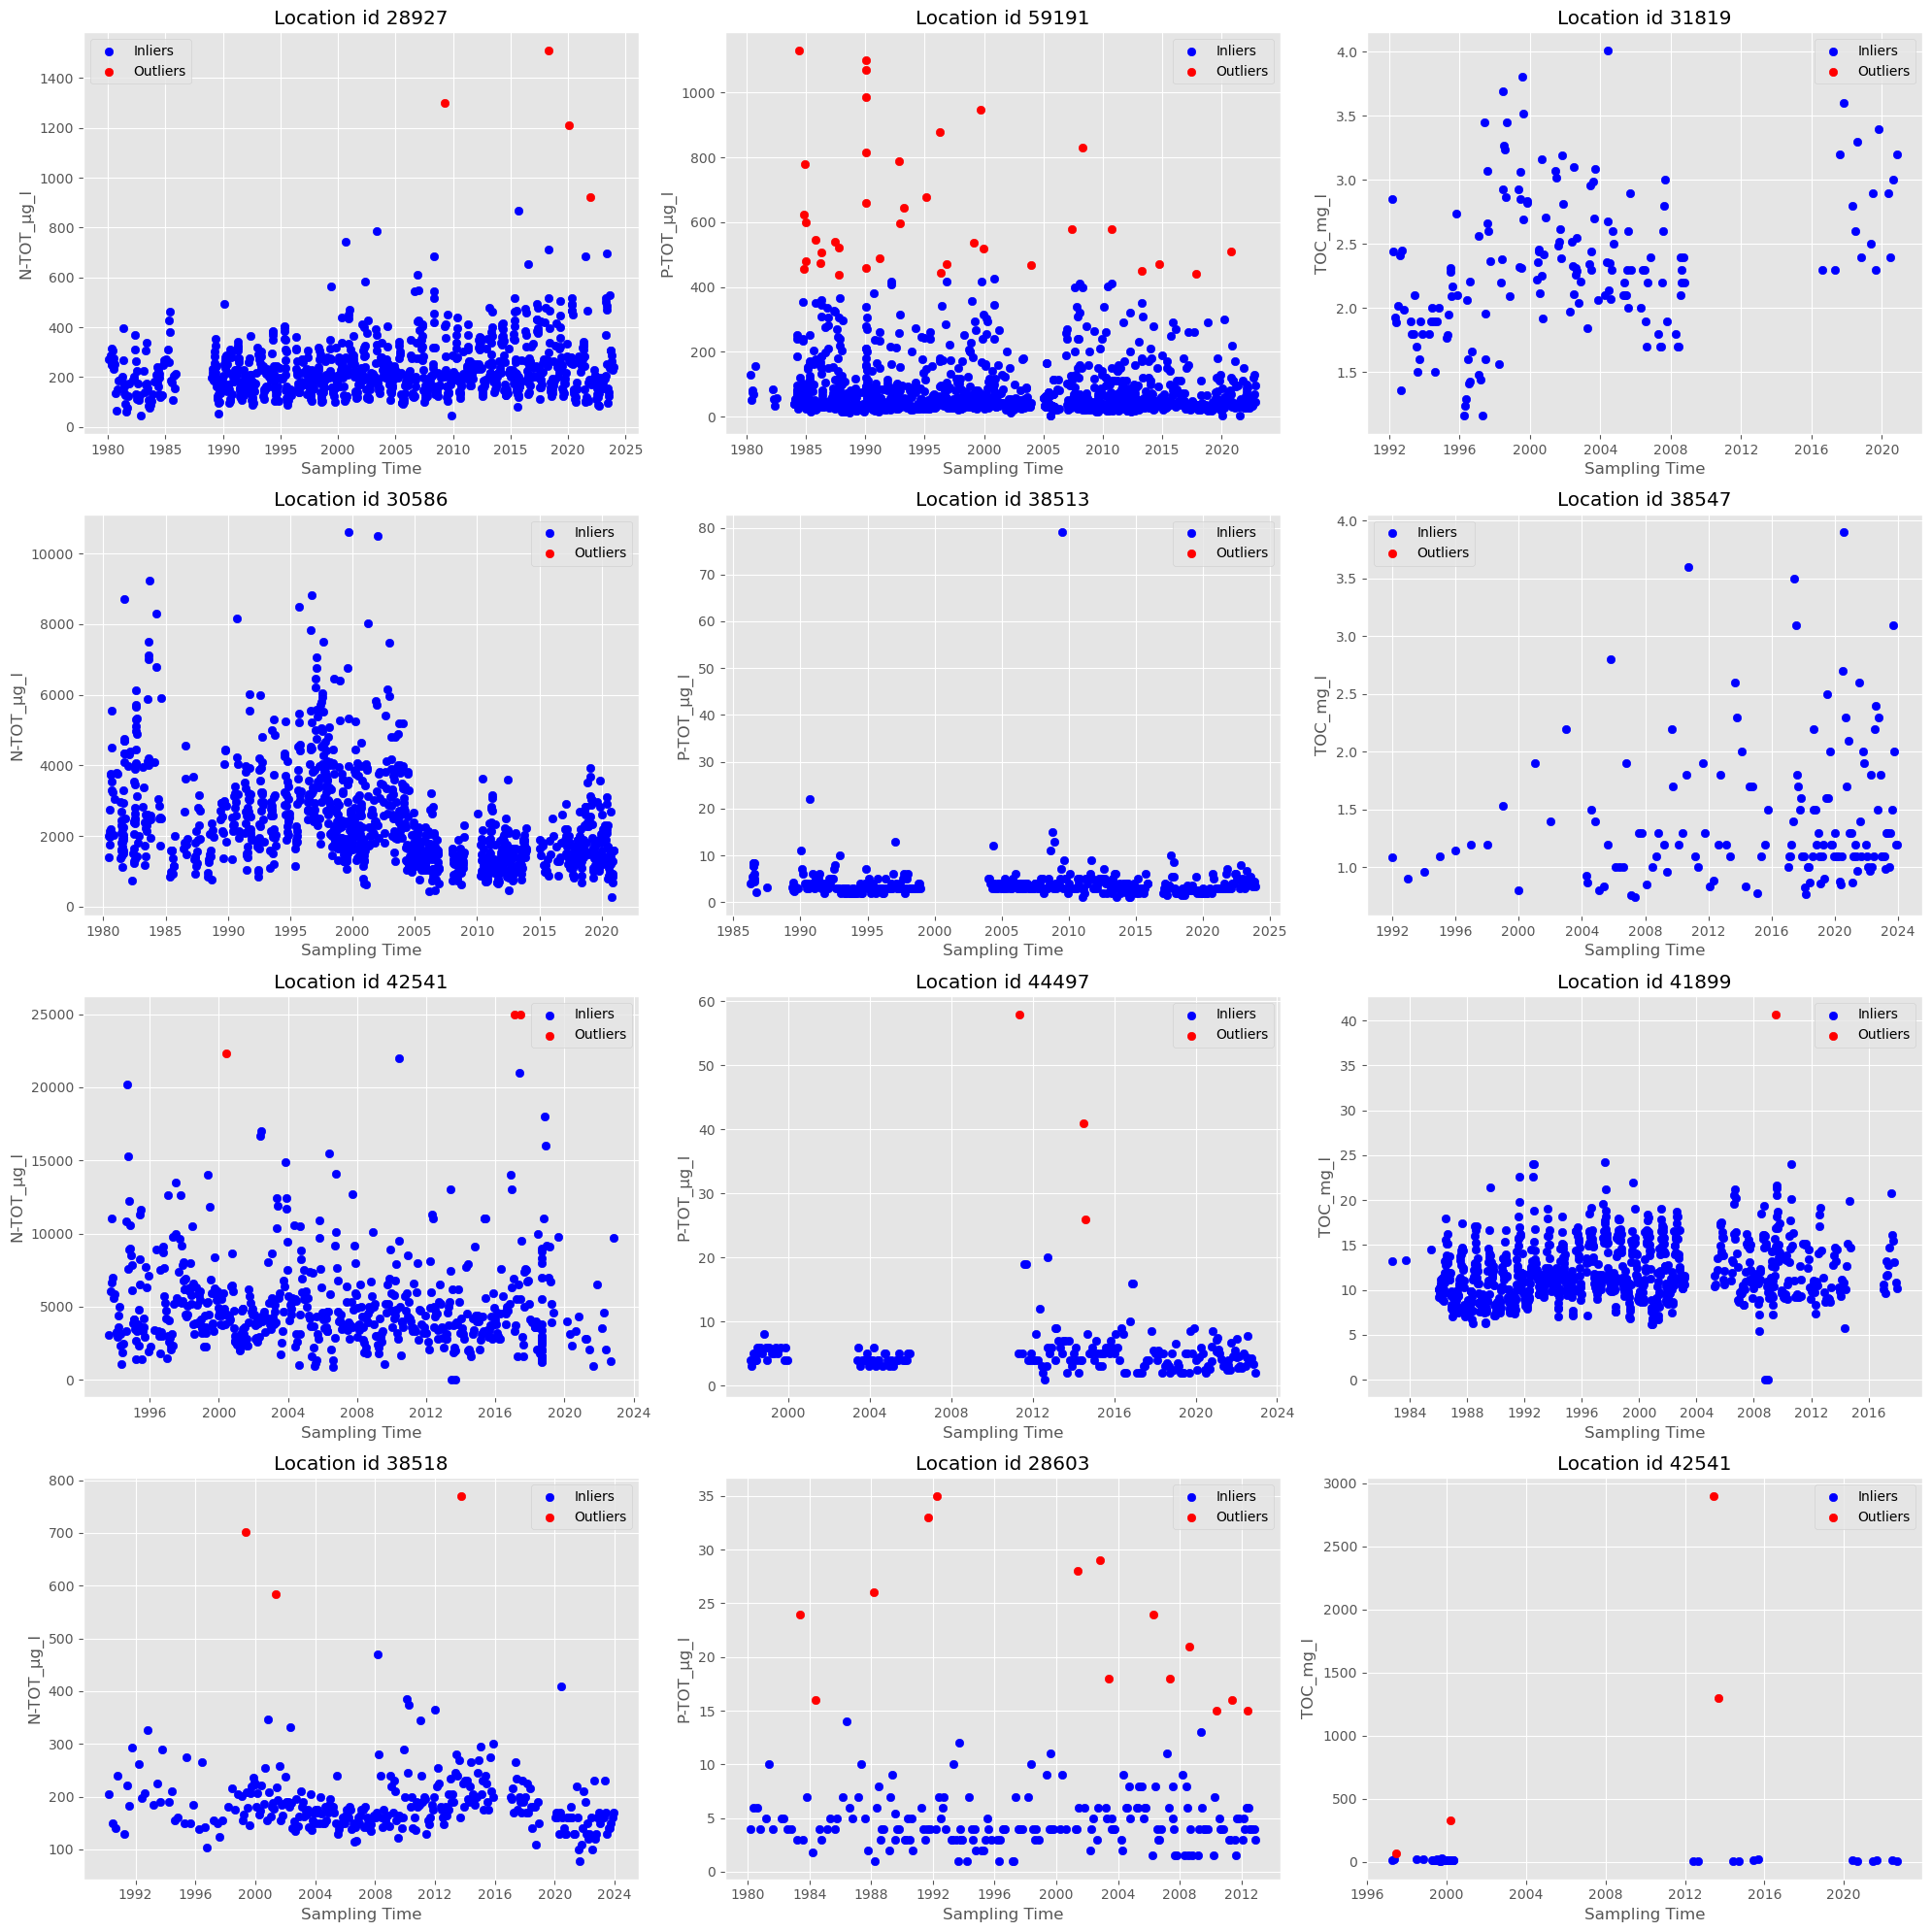

In [18]:
# Filter sites that have more than 30 years of observations
df_R['Year'] = df_R['SamplingTime'].dt.year
site_years = df_R.groupby('WaterLocationID')['Year'].nunique()
sites_with_30_years = site_years[site_years >= 30].index

# Randomly select a subset of WaterLocationIDs for each variable from sites with more than 30 years of observations
random_sites_ntot = random.sample(list(sites_with_30_years), 4)
random_sites_ptot = random.sample(list(sites_with_30_years), 4)
random_sites_toc = random.sample(list(sites_with_30_years), 4)


# Plot data for each randomly selected site and each variable separately
fig, axs = plt.subplots(4, len(variables), figsize=(20, 20))

for i, (site_id_ntot, site_id_ptot, site_id_toc) in enumerate(zip(random_sites_ntot, random_sites_ptot, random_sites_toc)):
    plot_site_data(df_R, site_id_ntot, 'N-TOT_µg_l', column_mapping, axs[i, 0])
    plot_site_data(df_R, site_id_ptot, 'P-TOT_µg_l', column_mapping, axs[i, 1])
    plot_site_data(df_R, site_id_toc, 'TOC_mg_l', column_mapping, axs[i, 2])

plt.tight_layout()
plt.show()

In [30]:
# Reorder columns
df_R = df_R[new_order]

# save as csv
df_R.to_csv("../data/cleaned/water_chemistry/ai_wc_outliers_flagged_rivers.csv", index=False)

### 4.3. Across all sites: Lakes

In [20]:
df_L.head()

,WaterLocationID,WaterLocationCode,Name,ActivityID,ActivityName,MediumID,SamplingTime,UpperDepth,LowerDepth,N-TOT_µg_l,P-TOT_µg_l,TOC_mg_l,lon,lat,WaterCategory
88,27839,001-27839,Bjørkelangen (BJØ1),ANNE,Annet,VF,1980-02-20,0.0,0.0,1280.0,54.0,NaN,11.532832,59.848034,L
89,27839,001-27839,Bjørkelangen (BJØ1),ANNE,Annet,VF,1980-02-20,1.0,1.0,1440.0,52.0,NaN,11.532832,59.848034,L
90,27839,001-27839,Bjørkelangen (BJØ1),ANNE,Annet,VF,1980-02-20,2.0,2.0,1560.0,43.0,NaN,11.532832,59.848034,L
91,27839,001-27839,Bjørkelangen (BJØ1),ANNE,Annet,VF,1980-02-20,5.0,5.0,1560.0,43.0,NaN,11.532832,59.848034,L
92,27839,001-27839,Bjørkelangen (BJØ1),ANNE,Annet,VF,1980-02-20,7.0,7.0,1520.0,46.0,NaN,11.532832,59.848034,L


In [21]:
# Estimate outliers 
# Apply the function to each column
df_L['global_outliers_ntot'] = double_mad_from_median(df_L['N-TOT_µg_l'], thresh=4)
df_L['global_outliers_ptot'] = double_mad_from_median(df_L['P-TOT_µg_l'], thresh=4)
df_L['global_outliers_toc'] = double_mad_from_median(df_L['TOC_mg_l'], thresh=4)

# Ensure NaN values are preserved in the original columns
df_L['global_outliers_ntot'] = df_L['global_outliers_ntot'].where(~df_L['N-TOT_µg_l'].isna(), np.nan)
df_L['global_outliers_ptot'] = df_L['global_outliers_ptot'].where(~df_L['P-TOT_µg_l'].isna(), np.nan)
df_L['global_outliers_toc'] = df_L['global_outliers_toc'].where(~df_L['TOC_mg_l'].isna(), np.nan)

df_L.info()

<class 'pandas.core.frame.DataFrame'>
Index: 71182 entries, 88 to 326551
Data columns (total 18 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   WaterLocationID       71182 non-null  int64         
 1   WaterLocationCode     71182 non-null  object        
 2   Name                  71182 non-null  object        
 3   ActivityID            71182 non-null  object        
 4   ActivityName          71182 non-null  object        
 5   MediumID              71182 non-null  object        
 6   SamplingTime          71182 non-null  datetime64[ns]
 7   UpperDepth            71182 non-null  float64       
 8   LowerDepth            71182 non-null  float64       
 9   N-TOT_µg_l            54208 non-null  float64       
 10  P-TOT_µg_l            56853 non-null  float64       
 11  TOC_mg_l              43392 non-null  float64       
 12  lon                   71182 non-null  float64       
 13  lat                

/tmp/ipykernel_500/2919434900.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_L['global_outliers_ntot'] = double_mad_from_median(df_L['N-TOT_µg_l'], thresh=4)
/tmp/ipykernel_500/2919434900.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_L['global_outliers_ptot'] = double_mad_from_median(df_L['P-TOT_µg_l'], thresh=4)
/tmp/ipykernel_500/2919434900.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value inst

In [22]:
# Filter the dataframe for False and True global outliers
df_ntot_false = df_L[df_L['global_outliers_ntot'] == False]
df_ptot_false = df_L[df_L['global_outliers_ptot'] == False]
df_toc_false = df_L[df_L['global_outliers_toc'] == False]

df_ntot_true = df_L[df_L['global_outliers_ntot'] == True]
df_ptot_true = df_L[df_L['global_outliers_ptot'] == True]
df_toc_true = df_L[df_L['global_outliers_toc'] == True]

# Total number of samples vs numeber of outliers detected by MAD
print(f"The total number of samples in the dataset is: {len(df_L['N-TOT_µg_l'].dropna())}")
print(f"The total number of outliers detected is: {len(df_ntot_true)}\n")
print(f"The total number of samples in the dataset is: {len(df_L['P-TOT_µg_l'].dropna())}")
print(f"The total number of outliers detected is: {len(df_ptot_true)}\n")
print(f"The total number of samples in the dataset is: {len(df_L['TOC_mg_l'].dropna())}")
print(f"The total number of outliers detected is: {len(df_toc_true)}\n")

The total number of samples in the dataset is: 54208
The total number of outliers detected is: 1187

The total number of samples in the dataset is: 56853
The total number of outliers detected is: 1996

The total number of samples in the dataset is: 43392
The total number of outliers detected is: 364



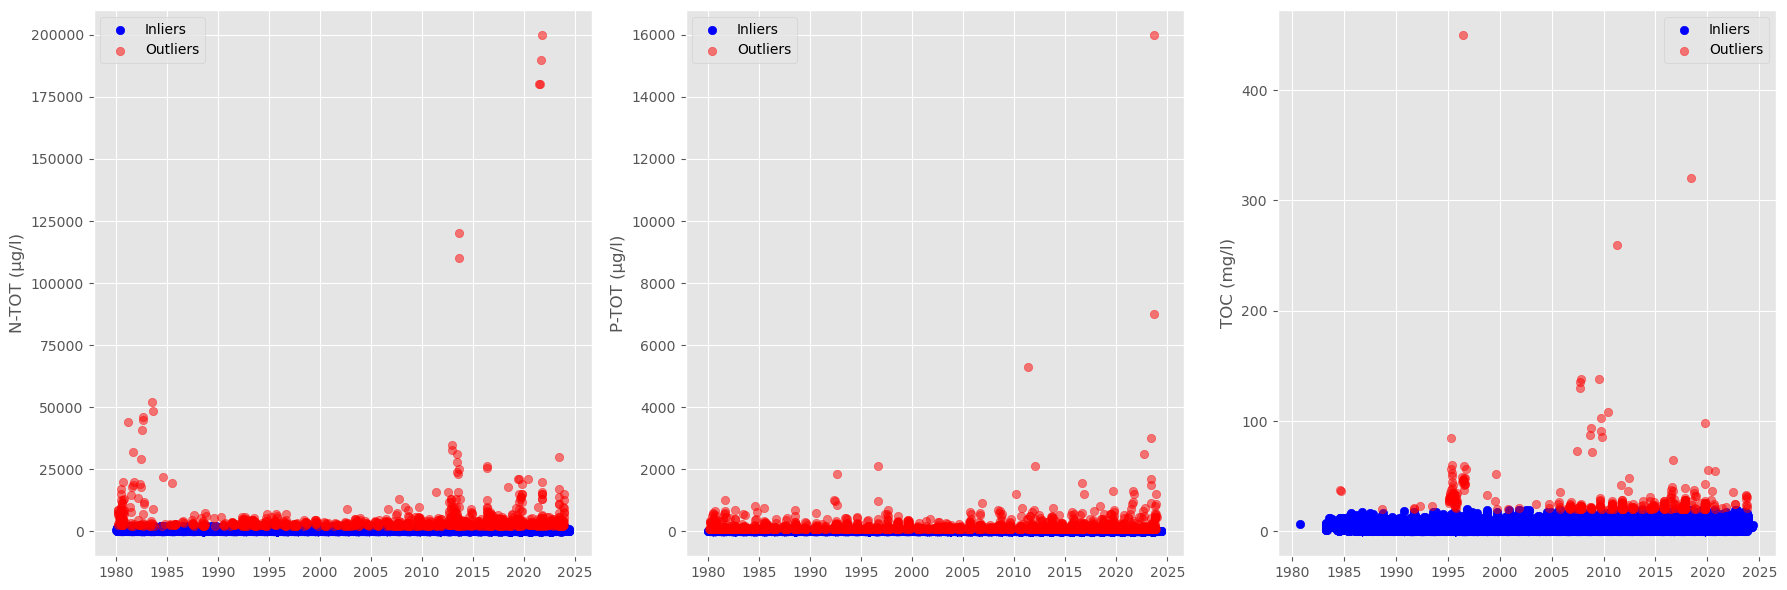

In [23]:
fig, axs = plt.subplots(1, 3, figsize=(18, 6))

# Plot for N-TOT
axs[0].scatter(df_ntot_false['SamplingTime'], df_ntot_false['N-TOT_µg_l'], color='blue', label='Inliers')
axs[0].scatter(df_ntot_true['SamplingTime'], df_ntot_true['N-TOT_µg_l'], color='red', label='Outliers', alpha= 0.5)
axs[0].set_ylabel('N-TOT (µg/l)')
axs[0].legend()

# Plot for P-TOT
axs[1].scatter(df_ptot_false['SamplingTime'], df_ptot_false['P-TOT_µg_l'], color='blue', label='Inliers')
axs[1].scatter(df_ptot_true['SamplingTime'], df_ptot_true['P-TOT_µg_l'], color='red', label='Outliers', alpha = 0.5)
axs[1].set_ylabel('P-TOT (µg/l)')
axs[1].legend()

# Plot for TOC
axs[2].scatter(df_toc_false['SamplingTime'], df_toc_false['TOC_mg_l'], color='blue', label='Inliers')
axs[2].scatter(df_toc_true['SamplingTime'], df_toc_true['TOC_mg_l'], color='red', label='Outliers', alpha = 0.5)
axs[2].set_ylabel('TOC (mg/l)')
axs[2].legend()

plt.tight_layout()
plt.show()

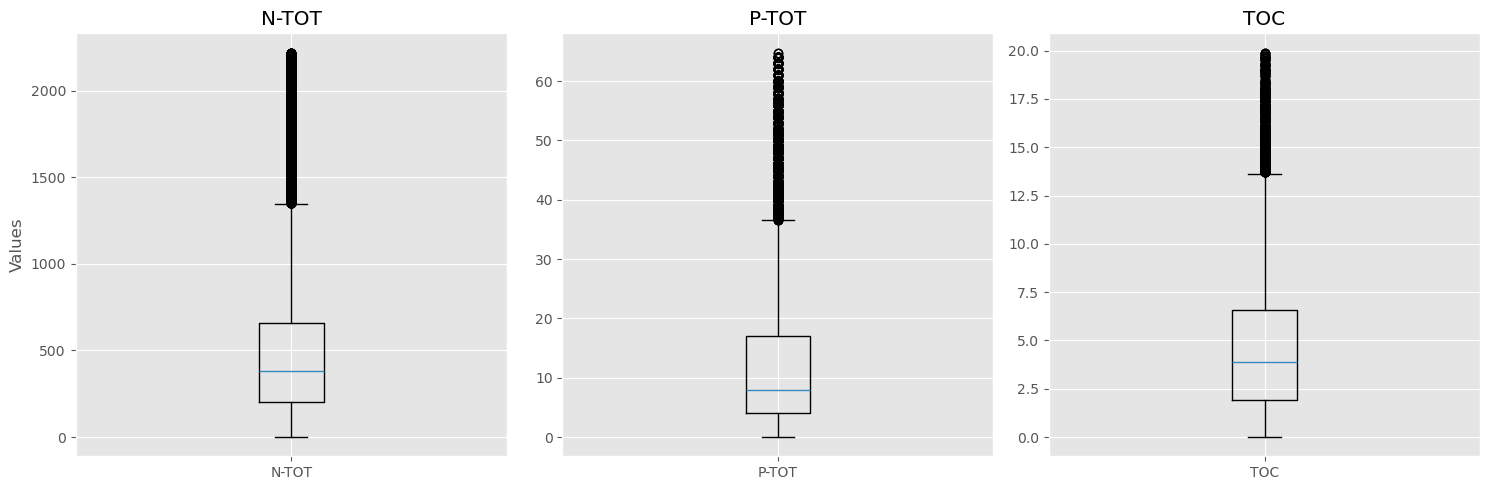

In [24]:
# Boxplots of inliers
plt.figure(figsize=(15, 5))

# Plot N-TOT boxplot
plt.subplot(1, 3, 1)
plt.boxplot(df_ntot_false['N-TOT_µg_l'].dropna(), labels=['N-TOT'])
plt.title('N-TOT')
plt.ylabel('Values')

# Plot P-TOT boxplot
plt.subplot(1, 3, 2)
plt.boxplot(df_ptot_false['P-TOT_µg_l'].dropna(), labels=['P-TOT'])
plt.title('P-TOT')

# Plot TOC boxplot
plt.subplot(1, 3, 3)
plt.boxplot(df_toc_false['TOC_mg_l'].dropna(), labels=['TOC'])
plt.title('TOC')

# Show the plots
plt.tight_layout()
plt.show()

### e. Sites individually: Lakes

/tmp/ipykernel_500/759149173.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_L['year'] = pd.to_datetime(df_L['SamplingTime']).dt.year


Number of unique water location IDs: 7321

N-TOT_µg_l: {'less_than_5': 3965, 'between_5_and_10': 303, 'between_10_and_20': 223, 'between_20_and_30': 42, 'between_30_and_40': 74, 'more_than_40': 13}

P-TOT_µg_l: {'less_than_5': 4645, 'between_5_and_10': 312, 'between_10_and_20': 271, 'between_20_and_30': 60, 'between_30_and_40': 11, 'more_than_40': 12}

TOC_mg_l: {'less_than_5': 5167, 'between_5_and_10': 522, 'between_10_and_20': 369, 'between_20_and_30': 32, 'between_30_and_40': 79, 'more_than_40': 0}



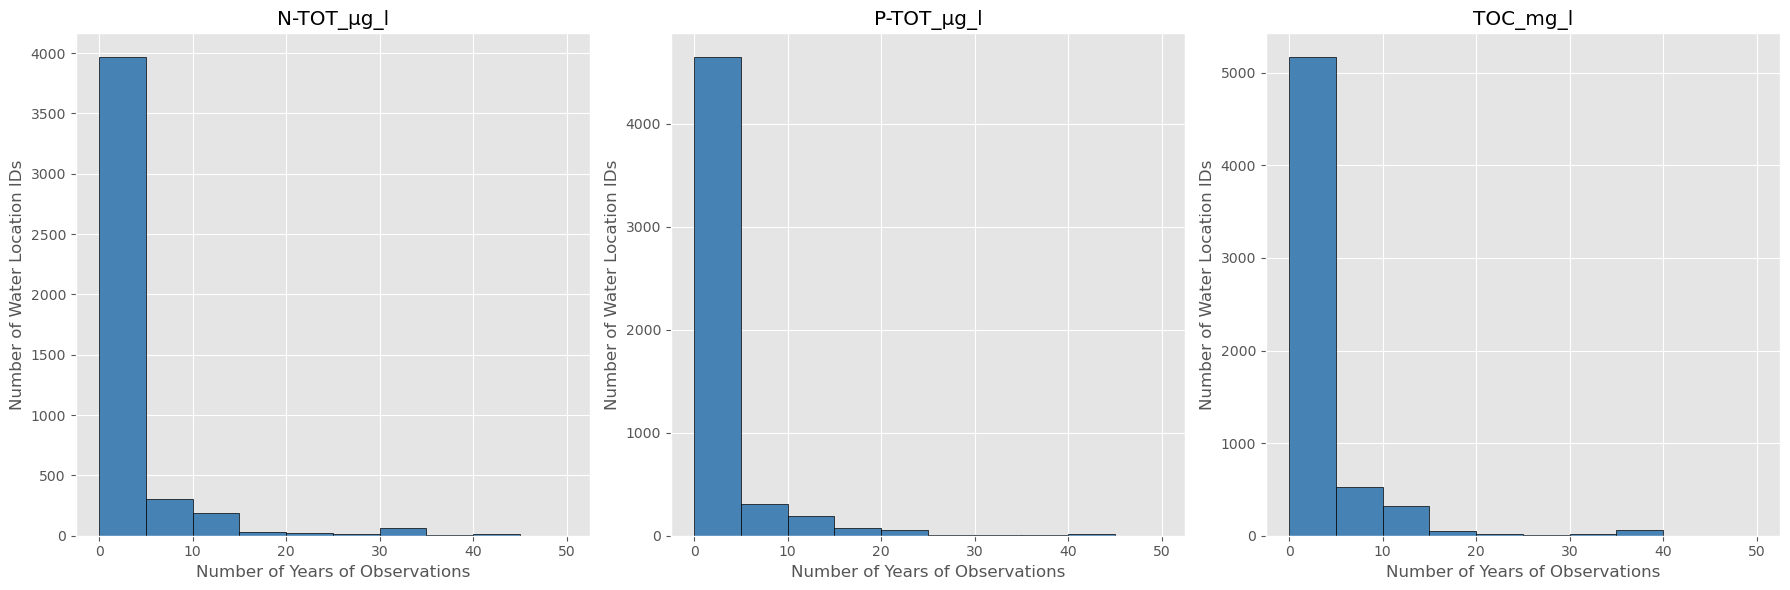

In [25]:
# Variables
variables = ['N-TOT_µg_l', 'P-TOT_µg_l', 'TOC_mg_l']

# Convert sampling time to year
df_L['year'] = pd.to_datetime(df_L['SamplingTime']).dt.year

# Count unique water location IDs
unique_ids = df_L['WaterLocationID'].nunique()
print(f"Number of unique water location IDs: {unique_ids}\n")


# Calculate and categorize the number of years of observations for each variable
for var in variables:
    years_of_observations = calculate_years_of_observations(df_L, var)
    categories = {
        'less_than_5': (years_of_observations < 5).sum(),
        'between_5_and_10': ((years_of_observations >= 5) & (years_of_observations < 10)).sum(),
        'between_10_and_20': ((years_of_observations >= 10) & (years_of_observations < 20)).sum(),
        'between_20_and_30': ((years_of_observations >= 20) & (years_of_observations < 30)).sum(),
        'between_30_and_40': ((years_of_observations >= 30) & (years_of_observations < 40)).sum(),
        'more_than_40': (years_of_observations >= 40).sum()
    }
    print(f"{var}: {categories}\n")

# Create subplots
fig, axs = plt.subplots(1, 3, figsize=(18, 6))

# Create histograms for each variable
for i, var in enumerate(variables):
    years_of_observations = calculate_years_of_observations(df_L, var)
    
    axs[i].hist(years_of_observations, bins=[0, 5, 10, 15, 20, 25, 30, 35, 40, 45, 50], edgecolor='black', color='steelblue')
    axs[i].set_xlabel('Number of Years of Observations')
    axs[i].set_ylabel('Number of Water Location IDs')
    axs[i].set_title(f'{var}')
    axs[i].grid(True)

plt.tight_layout()
plt.show()

In [26]:
# Apply the outlier detection function to each group and create new columns with specified names
for original_column, outlier_column in column_mapping.items():
    df_L[outlier_column] = df_L.groupby('WaterLocationID').apply(detect_outliers, column=original_column, thresh=7).reset_index(level=0, drop=True)
    print(f"Processed column: {original_column} -> {outlier_column}")  # Debugging step to ensure each column is processed

# Check the result
df_L.head()

/opt/conda/lib/python3.11/site-packages/numpy/lib/nanfunctions.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/opt/conda/lib/python3.11/site-packages/numpy/core/fromnumeric.py:3504: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/opt/conda/lib/python3.11/site-packages/numpy/core/_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/tmp/ipykernel_500/2712433371.py:3: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_L[outlier_column] = df_L.groupby('WaterLocationID').apply(detect_outliers, column=original_column, thresh=7).reset_index(level=0, d

Processed column: N-TOT_µg_l -> site_outliers_ntot


/tmp/ipykernel_500/2712433371.py:3: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_L[outlier_column] = df_L.groupby('WaterLocationID').apply(detect_outliers, column=original_column, thresh=7).reset_index(level=0, drop=True)
/tmp/ipykernel_500/2712433371.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_L[outlier_column] = df_L.groupby('WaterLocationID').apply(detect_outliers, column=original_column, thresh=7).reset_index(level=0, drop=True)
/opt/cond

Processed column: P-TOT_µg_l -> site_outliers_ptot
Processed column: TOC_mg_l -> site_outliers_toc


/tmp/ipykernel_500/2712433371.py:3: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_L[outlier_column] = df_L.groupby('WaterLocationID').apply(detect_outliers, column=original_column, thresh=7).reset_index(level=0, drop=True)
/tmp/ipykernel_500/2712433371.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_L[outlier_column] = df_L.groupby('WaterLocationID').apply(detect_outliers, column=original_column, thresh=7).reset_index(level=0, drop=True)


,WaterLocationID,WaterLocationCode,Name,ActivityID,ActivityName,MediumID,SamplingTime,UpperDepth,LowerDepth,N-TOT_µg_l,...,lon,lat,WaterCategory,global_outliers_ntot,global_outliers_ptot,global_outliers_toc,year,site_outliers_ntot,site_outliers_ptot,site_outliers_toc
88,27839,001-27839,Bjørkelangen (BJØ1),ANNE,Annet,VF,1980-02-20,0.0,0.0,1280.0,...,11.532832,59.848034,L,False,False,NaN,1980,False,False,NaN
89,27839,001-27839,Bjørkelangen (BJØ1),ANNE,Annet,VF,1980-02-20,1.0,1.0,1440.0,...,11.532832,59.848034,L,False,False,NaN,1980,False,False,NaN
90,27839,001-27839,Bjørkelangen (BJØ1),ANNE,Annet,VF,1980-02-20,2.0,2.0,1560.0,...,11.532832,59.848034,L,False,False,NaN,1980,False,False,NaN
91,27839,001-27839,Bjørkelangen (BJØ1),ANNE,Annet,VF,1980-02-20,5.0,5.0,1560.0,...,11.532832,59.848034,L,False,False,NaN,1980,False,False,NaN
92,27839,001-27839,Bjørkelangen (BJØ1),ANNE,Annet,VF,1980-02-20,7.0,7.0,1520.0,...,11.532832,59.848034,L,False,False,NaN,1980,False,False,NaN


/tmp/ipykernel_500/1052508045.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_L['Year'] = df_L['SamplingTime'].dt.year


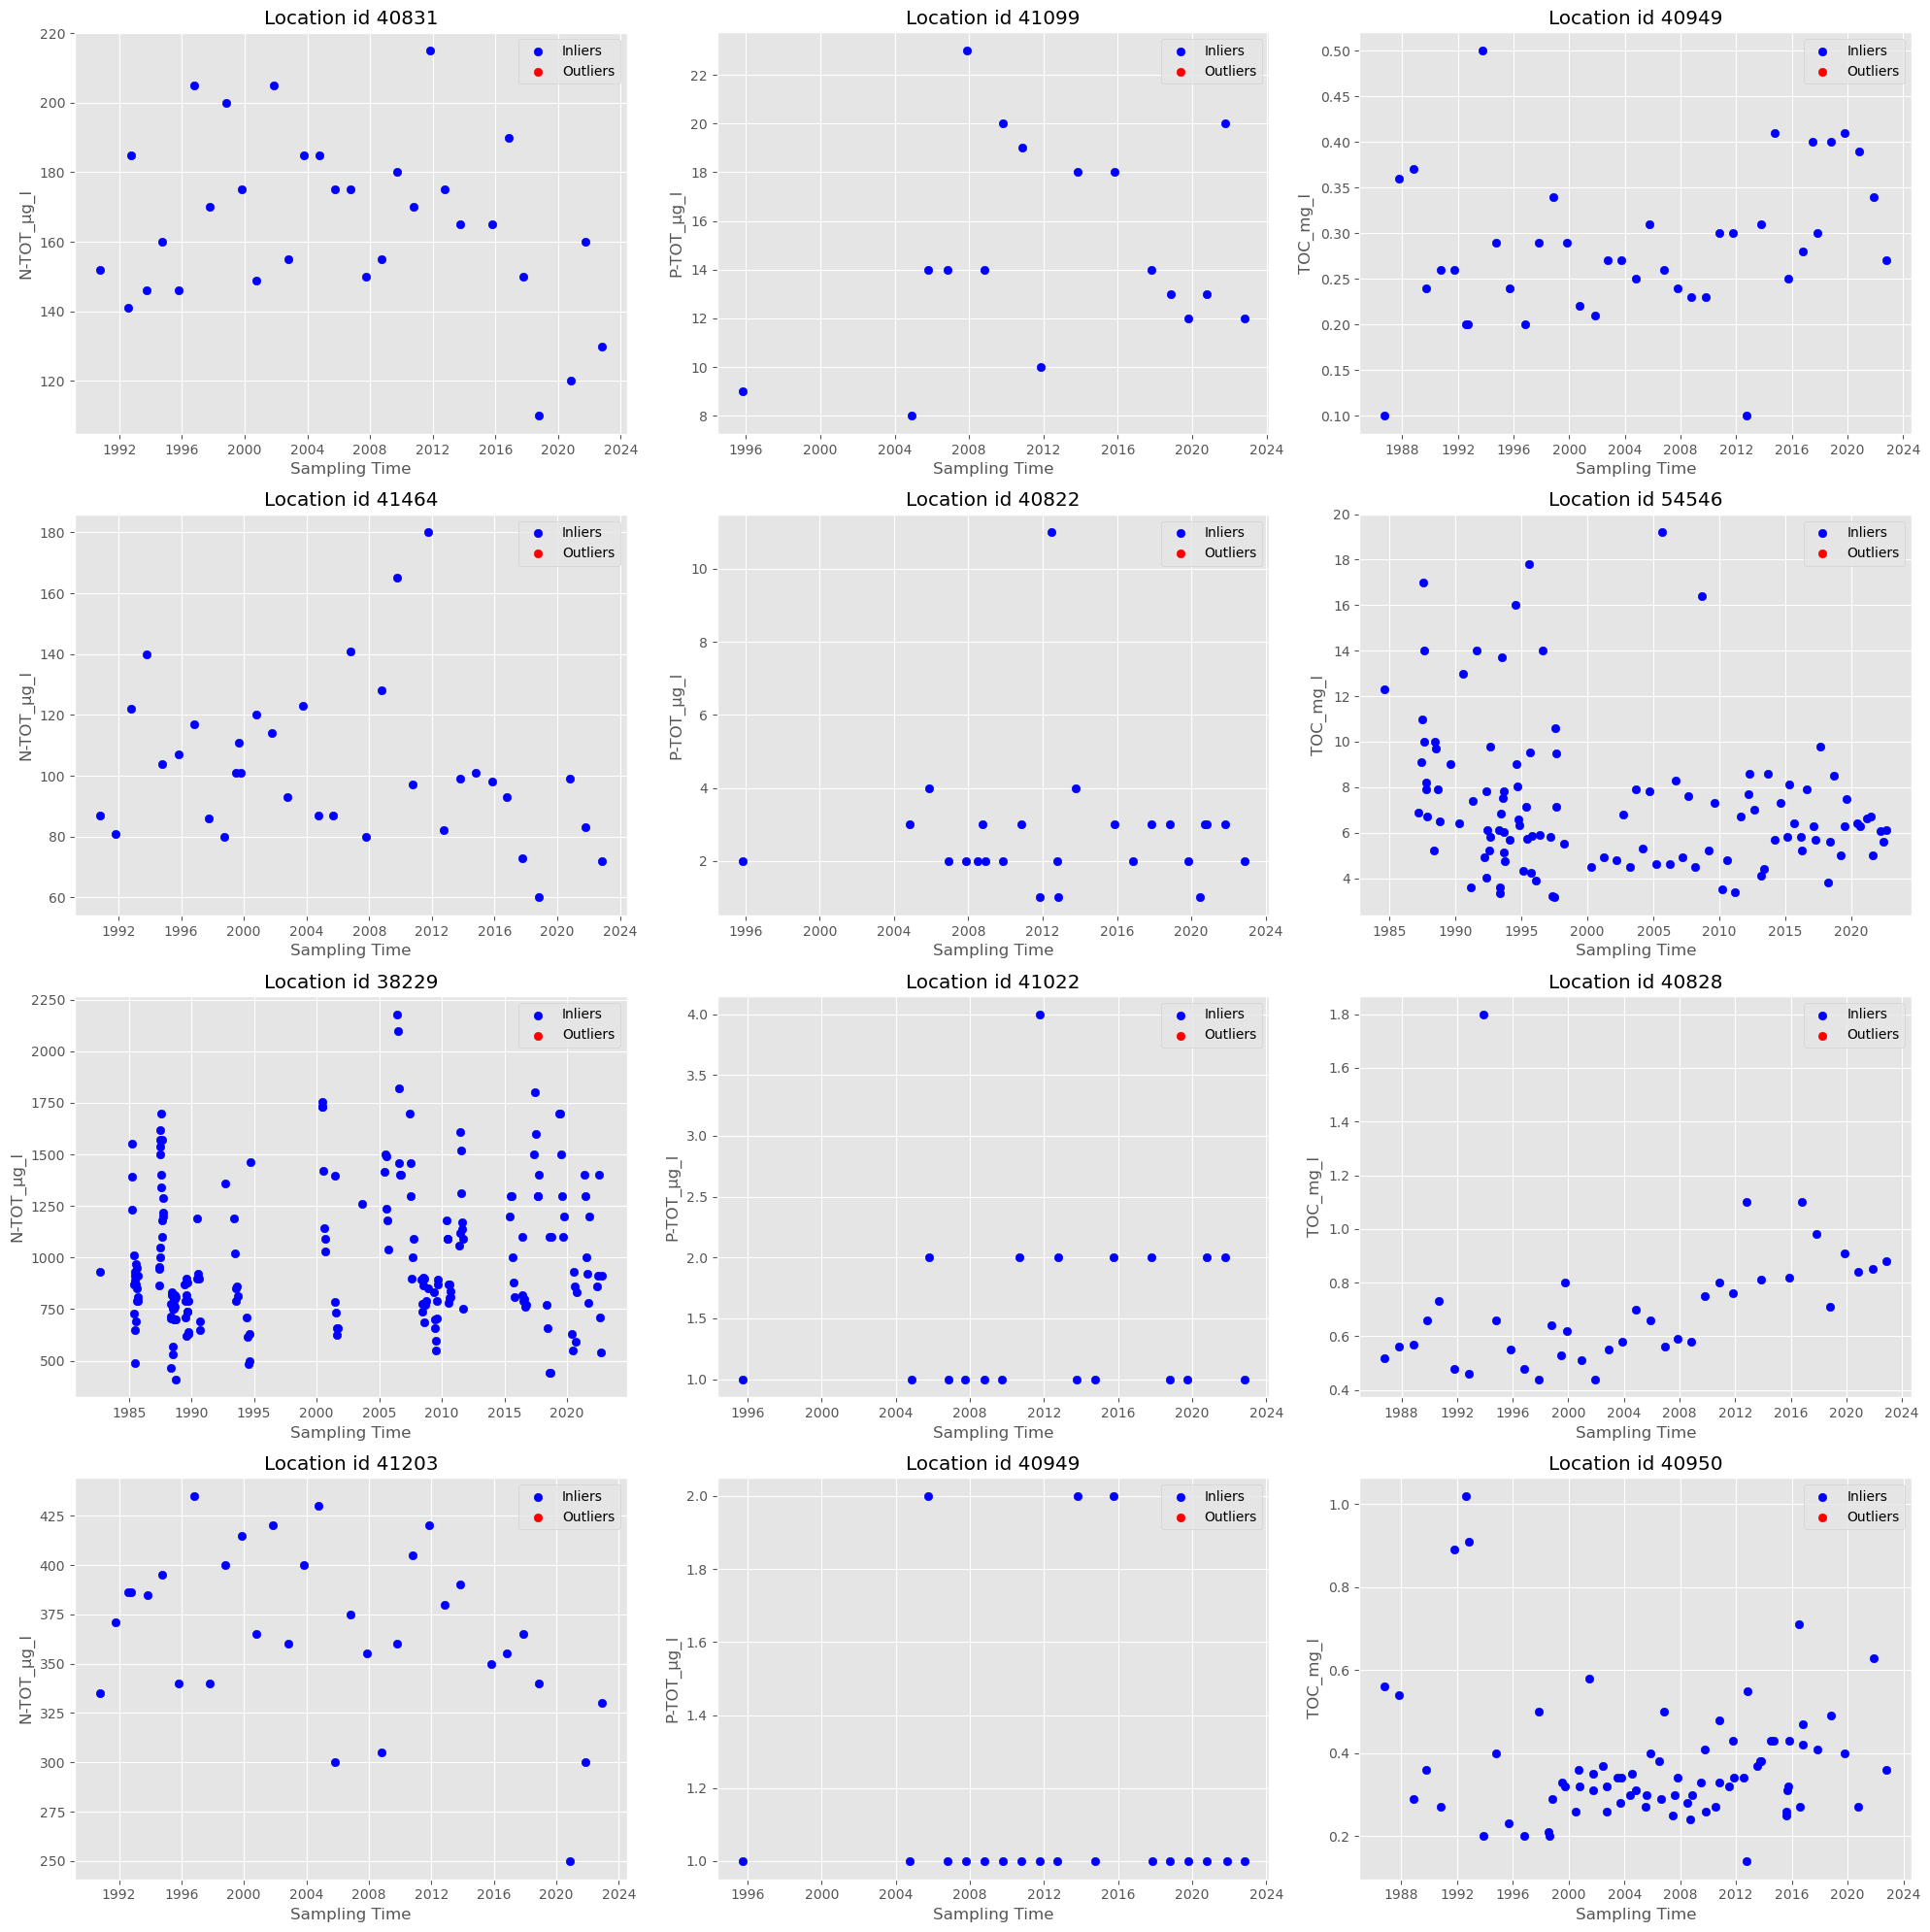

In [27]:
# Filter sites that have more than 30 years of observations
df_L['Year'] = df_L['SamplingTime'].dt.year
site_years = df_L.groupby('WaterLocationID')['Year'].nunique()
sites_with_30_years = site_years[site_years >= 30].index

# Randomly select a subset of WaterLocationIDs for each variable from sites with more than 30 years of observations
random_sites_ntot = random.sample(list(sites_with_30_years), 4)
random_sites_ptot = random.sample(list(sites_with_30_years), 4)
random_sites_toc = random.sample(list(sites_with_30_years), 4)


# Plot data for each randomly selected site and each variable separately
fig, axs = plt.subplots(4, len(variables), figsize=(20, 20))

for i, (site_id_ntot, site_id_ptot, site_id_toc) in enumerate(zip(random_sites_ntot, random_sites_ptot, random_sites_toc)):
    plot_site_data(df_L, site_id_ntot, 'N-TOT_µg_l', column_mapping, axs[i, 0])
    plot_site_data(df_L, site_id_ptot, 'P-TOT_µg_l', column_mapping, axs[i, 1])
    plot_site_data(df_L, site_id_toc, 'TOC_mg_l', column_mapping, axs[i, 2])

plt.tight_layout()
plt.show()

In [29]:
# Reorder columns
df_L = df_L[new_order]

# save as csv
df_L.to_csv("../data/cleaned/water_chemistry/ai_wc_outliers_flagged_lakes.csv", index = False)